# ML20 · NB0 · Exploratory Data Analysis
**Machine Learning I · Group Project 2026-27 · The Guild of Gentle Landings**

**Goal of the project.** Predict, **one hour after an aviation accident**, whether it was **fatal** (`fatal = 1`: at least one person died). The Kaggle metric is the **F1 score of the fatal class**.

**Goal of this notebook.** Understand the data *before* touching it: distributions, missing values, odd values, relations between features and with the target. Every finding ends with a **→ NB1** decision or question. Following the brief, **NB0 does not change the data and does not train models**. When something has to be cleaned just to look at it, that is done on a throw-away copy.

**Contents**
1. Overview (Person 1): first look, target, missing values, hidden missing values, learn vs predict, correlations
2. When and where (Person 2)
3. Weather (Person 3)
4. Aircraft and engine (Person 4)
5. Pilot and flight (Person 5)
6. Interactions between groups (Person 5)
7. Findings and decisions for NB1 (all parts)

## 0. Setup
One cell shared by every part: imports and library versions, `SEED`, plot style, loading `learn.csv` / `predict.csv` from this folder (relative paths), `BASE` (the base fatal rate) and two helper functions, `plot_cat_vs_target` and `plot_num_vs_target`, so all sections use the same kind of plot.

In [1]:
# ===== SHARED SETUP (all parts use this) =====
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print(f"numpy {np.__version__} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")

SEED = 5
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

learn = pd.read_csv("learn.csv")
predict = pd.read_csv("predict.csv")

BASE = learn["fatal"].mean()
print(f"learn {learn.shape} · predict {predict.shape} · base fatal rate {BASE:.1%}")


def plot_cat_vs_target(df, col, min_n=30, top=15, ax=None, title=None):
    """Fatal rate per category (with n on top of each bar). Does not modify df."""
    g = (df.groupby(col, dropna=False)["fatal"].agg(rate="mean", n="size")
           .query("n >= @min_n").sort_values("n", ascending=False).head(top))
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    ax.bar(range(len(g)), g["rate"], color="#3b7ea1")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index])
    ax.axhline(BASE, color="crimson", ls="--", lw=1, label=f"base rate {BASE:.1%}")
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("fatal rate"); ax.set_title(title or f"Fatal rate by {col} (groups with n >= {min_n})")
    ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
    return g


def plot_num_vs_target(df, col, q=8, ax=None, title=None):
    """Fatal rate per quantile bin of a numeric column. Does not modify df."""
    s = df[col]
    bins = pd.qcut(s, q=q, duplicates="drop")
    g = df.groupby(bins, observed=True)["fatal"].agg(rate="mean", n="size")
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    ax.bar(range(len(g)), g["rate"], color="#3b7ea1")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=7)
    ax.axhline(BASE, color="crimson", ls="--", lw=1)
    ax.set_ylabel("fatal rate"); ax.set_title(title or f"Fatal rate by quantile bins of {col}")
    return g

numpy 2.1.3 · pandas 2.2.3 · matplotlib 3.10.0
learn (16979, 42) · predict (4245, 41) · base fatal rate 17.0%


# 1. Overview (Person 1)
## 1.1 First look at the data

In [2]:
learn.head()

,row_id,ev_year,ev_month,ev_country,ev_dow,ev_hour,light_cond,wx_cond_basic,sky_cond_ceil,sky_cond_nonceil,gust_ind,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,...,far_part,acft_category,homebuilt,fixed_retractable,type_fly,flt_plan_filed,second_pilot,acft_make,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_type,carb_fuel_injection,eng_power,pilot_age,pilot_sex,pilot_med_certf,phase,fatal
0,A00001,2018,9,USA,Th,19.0,DAYL,VMC,NONE,CLER,T,0,10.0,59,15.0,49,38,7.0,0,30.06,...,091,air,N,FIXD,PERS,NONE,N,PIPER,0,1.0,2.0,1956.0,REC,CARB,NaN,71.0,M,CL3,Landing,0
1,A00002,2011,7,USA,Sa,17.0,DAYL,VMC,NONE,CLER,T,0,5.0,70,21.1,56,0,3.0,0,29.91,...,091,AIR,n,FIXD,INST,NONE,n,AMERICAN AVIATION,0,1.0,2.0,NaN,REC,CARB,108.0,17.0,M,CL1,Maneuvering,1
2,A00004,2013,7,USA,Su,22.0,DAYL,VMC,UNK,FEW,F,0,10.0,80,26.7,73,0,10.0,17,30.06,...,091,AIR,N,FIXD,PERS,UNK,N,LUSCOMBE,0,1.0,2.0,NaN,REC,CARB,84.0,46.0,M,CL3,Landing,0
3,A00005,2019,9,USA,Fr,0.0,DAYL,VMC,BKN,NaN,T,10208,10.0,80,26.7,33,261,6.0,0,30.07,...,091,air,n,FIXD,PERS,NONE,N,AMERICAN AVIATION,1,1.0,4.0,1976.0,REC,CARB,150.0,31.0,M,CL1,Enroute,1
4,A00006,2008,4,USA,Su,1.0,DAYL,VMC,NONE,CLER,F,0,10.0,62,16.7,36,261,13.0,18,29.90,...,091,AIR,N,FIXD,PERS,NONE,n,CESSNA,0,1.0,4.0,NaN,REC,CARB,174.0,68.0,M,CL3,Approach,0


In [3]:
predict.head()

,row_id,ev_year,ev_month,ev_country,ev_dow,ev_hour,light_cond,wx_cond_basic,sky_cond_ceil,sky_cond_nonceil,gust_ind,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,...,apt_elev,far_part,acft_category,homebuilt,fixed_retractable,type_fly,flt_plan_filed,second_pilot,acft_make,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_type,carb_fuel_injection,eng_power,pilot_age,pilot_sex,pilot_med_certf,phase
0,A00003,2015,6,USA,Mo,16.0,DAYL,VMC,NaN,NaN,T,0,10.0,75,23.9,37,183,4.0,0,29.97,...,76.0,091,AIR,N,RETR,PERS,NONE,n,SHORT BROTHERS PLC,1,1.0,2.0,1987.0,TP,NaN,0.0,59.0,M,CL2,Maneuvering
1,A00009,2020,8,USA,Fr,19.0,DAYL,VMC,BKN,NaN,F,3832,10.0,75,23.9,64,70,7.0,0,29.95,...,NaN,137,AIR,N,FIXD,AAPL,NONE,N,AIR TRACTOR,0,1.0,1.0,2018.0,TP,NaN,NaN,55.0,M,CL2,Maneuvering
2,A00023,2019,2,USA,We,2.0,NDRK,VMC,NONE,CLER,F,0,10.0,0,-17.8,0,34,12.0,0,0.00,...,NaN,091,AIR,n,FIXD,PERS,NONE,N,CESSNA,0,1.0,4.0,1974.0,REC,CARB,NaN,31.0,M,CL1,Enroute
3,A00025,2021,9,USA,Tu,19.0,DAYL,VMC,NaN,SCAT,T,0,NaN,87,30.6,72,201,3.0,0,30.05,...,NaN,091,AIR,N,RETR,PERS,NONE,Y,PIPER,1,2.0,4.0,2001.0,REC,CARB,185.0,24.0,M,CL1,Enroute
4,A00034,2016,8,USA,Mo,7.0,NITE,VMC,NONE,CLER,T,0,10.0,90,32.2,74,194,7.0,0,29.80,...,418.0,091,AIR,N,RETR,PERS,NONE,n,BEECH,1,1.0,5.0,1983.0,REC,FINJ,272.0,60.0,F,CL2,Initial climb


Predict has one less column than learn, which is "fatal", because that is the column we are trying to predict.

In [4]:
learn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16979 entries, 0 to 16978
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   row_id               16979 non-null  object 
 1   ev_year              16979 non-null  int64  
 2   ev_month             16979 non-null  int64  
 3   ev_country           16979 non-null  object 
 4   ev_dow               16979 non-null  object 
 5   ev_hour              16960 non-null  float64
 6   light_cond           16953 non-null  object 
 7   wx_cond_basic        16960 non-null  object 
 8   sky_cond_ceil        14977 non-null  object 
 9   sky_cond_nonceil     14158 non-null  object 
 10  gust_ind             16979 non-null  object 
 11  sky_ceil_ht          16979 non-null  int64  
 12  vis_sm               16258 non-null  float64
 13  wx_temp              16979 non-null  int64  
 14  wx_temp_c            16979 non-null  float64
 15  wx_dew_pt            16979 non-null 

This dataset ha 16,979 rows and 42 columns of which 40 are features, one is the `row_id` and the last one the target `fatal`. There are 21 text (object) columns and 21 numeric ones.
Several numeric columns are `float64` only because they contain NaN (`num_eng`, `total_seats`, `acft_year`, `pilot_age`...). They are really integers.
`far_part` is read as text because it mixes codes such as `091` and `PUBU`. That is correct: it is a category, not a number, and the leading zeros must be kept.
Some numeric columns are really categories or flags: `ev_month`, `ev_hour` (cyclical), `ifr_equipped_cert` (0/1).

**→ NB1:** set the type of each column explicitly (numeric, categorical, binary) instead of trusting what pandas guesses.

In [5]:
print("duplicated rows - learn:", learn.duplicated().sum(), "· predict:", predict.duplicated().sum())
print("duplicated row_id - learn:", learn.row_id.duplicated().sum(), "· predict:", predict.row_id.duplicated().sum())
print("row_id in both files:", learn.row_id.isin(predict.row_id).sum())
feats = learn.columns.drop(["row_id", "fatal"])
print("duplicated feature rows (ignoring row_id) - learn:", learn[feats].duplicated().sum(),
      "· across learn+predict:", pd.concat([learn[feats], predict[feats]]).duplicated().sum())

duplicated rows - learn: 0 · predict: 0
duplicated row_id - learn: 0 · predict: 0
row_id in both files : 0
duplicated feature rows (ignoring row_id) - learn: 0 · across learn+predict: 0


There are no duplicated rows and no duplicated `row_id`, and no `row_id` appears in both files. There are also no rows with identical features under a different id, so no accident was entered twice, inside `learn` or across the two files.

**→ NB1:** nothing to remove.

In [6]:
card = pd.DataFrame({"n_unique_learn": learn.nunique(), "n_unique_predict": predict.nunique()})
card["dtype"] = learn.dtypes.astype(str)
card.sort_values("n_unique_learn")

,n_unique_learn,n_unique_predict,dtype
ev_country,1,1.0,object
ifr_equipped_cert,2,2.0,int64
gust_ind,2,2.0,object
fixed_retractable,2,2.0,object
fatal,2,NaN,int64
pilot_sex,2,2.0,object
carb_fuel_injection,2,2.0,object
wx_cond_basic,3,3.0,object
homebuilt,4,4.0,object
second_pilot,4,4.0,object


- **`ev_country` has a single value (`USA`)** in both files, so it carries no information.
- **Binary columns** (`gust_ind`, `ifr_equipped_cert`, `fixed_retractable`, `carb_fuel_injection`, `pilot_sex`): two values each. `homebuilt` and `second_pilot` show **4** values because of mixed case (`Y`/`y`, `N`/`n`), see 1.4.
- **High-cardinality text:** `acft_make` has ~2,900 distinct values, so it needs special treatment (Part 4).
- `acft_category` has 19 values in `learn`, many of them the same category in another case (`AIR`/`air`, `HELI`/`heli`).

**→ NB1:** drop `ev_country`; unify case before counting categories.

In [60]:
# Is wx_temp_c just wx_temp converted to Celsius?
conv = (learn["wx_temp"] - 32) * 5 / 9
diff = (conv - learn["wx_temp_c"]).abs()
print(f"max |(F-32)*5/9 - wx_temp_c| = {diff.max():.3f} °C  (rows with diff > 0.05: {(diff > 0.05).sum()})")
print("Spearman correlation:", round(learn["wx_temp"].corr(learn["wx_temp_c"], method="spearman"), 4))
print("\nrows with wx_temp == 0 °F:", (learn.wx_temp == 0).sum(),
      "→ wx_temp_c =", learn.loc[learn.wx_temp == 0, "wx_temp_c"].unique())
print("months of those rows:", learn.loc[learn.wx_temp == 0, "ev_month"].value_counts().sort_index().to_dict())

max |(F-32)*5/9 - wx_temp_c| = 0.044 °C  (rows with diff > 0.05: 0)
Spearman correlation: 1.0

rows with wx_temp == 0 °F: 855 → wx_temp_c = [-17.8]
months of those rows: {1: 46, 2: 45, 3: 44, 4: 76, 5: 81, 6: 119, 7: 114, 8: 103, 9: 91, 10: 50, 11: 39, 12: 47}


- `wx_temp_c` is exactly `wx_temp` converted to Celsius (differences < 0.05 °C, only rounding). It is a **perfectly redundant** column, it adds nothing, and it would double-count temperature in linear or distance-based models.
- 0 °F (−17.8 °C) appears in hundreds of rows **spread over all months, including summer**. That is not plausible weather; it is a missing-value code that also got converted (see 1.4).

**→ NB1:** drop `wx_temp_c`; treat `wx_temp = 0` as missing (decided together with Part 3).

## 1.2 The target: `fatal`

           n  share
fatal              
0      14090   0.83
1       2889   0.17


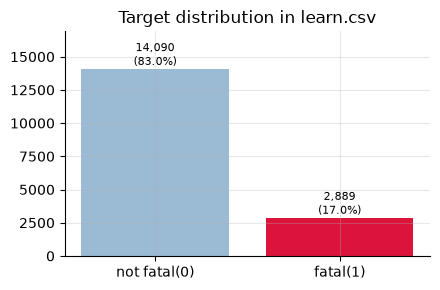

'always 0' → F1 = 0 (it never finds a fatal accident), accuracy = 83.0%
'always 1' → precision = 0.170, recall = 1, F1 = 0.291, accuracy = 17.0%


In [63]:
counts = learn["fatal"].value_counts().sort_index()
print(pd.DataFrame({"n": counts, "share": (counts / counts.sum()).round(3)}))

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(["not fatal(0)", "fatal(1)"], counts.values, color=["#9bbbd4", "crimson"])
for i, n in enumerate(counts.values):
    ax.text(i, n, f"{n:,}\n({n / counts.sum():.1%})", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, counts.max() * 1.2); ax.set_title("Target distribution in learn.csv")
plt.tight_layout(); plt.show()

# F1 of the two trivial strategies, to understand the metric
p = BASE
print(f"'always 0' → F1 = 0 (it never finds a fatal accident), accuracy = {1 - p:.1%}")
print(f"'always 1' → precision = {p:.3f}, recall = 1, F1 = {2 * p / (1 + p):.3f}, accuracy = {p:.1%}")

- The classes are **imbalanced**: about **1 accident in 6 is fatal** (≈17%), as the brief says.
- This is why **accuracy is the wrong metric**. Predicting "never fatal" gives ~83% accuracy and F1 = 0. Predicting "always fatal" gives F1 ≈ 0.29. **Any real model has to beat F1 ≈ 0.29.**
- F1 on class 1 balances precision and recall of the fatal class, so the **decision threshold** matters: 0.5 on predicted probabilities will probably not be optimal.

**→ NB1:** use **stratified** splits / cross-validation; evaluate with F1 (also report precision and recall); try class weights or resampling **inside** the CV only; tune the decision threshold on validation data, never on `predict`.

## 1.3 Missing values

23 of 40 features have missing values


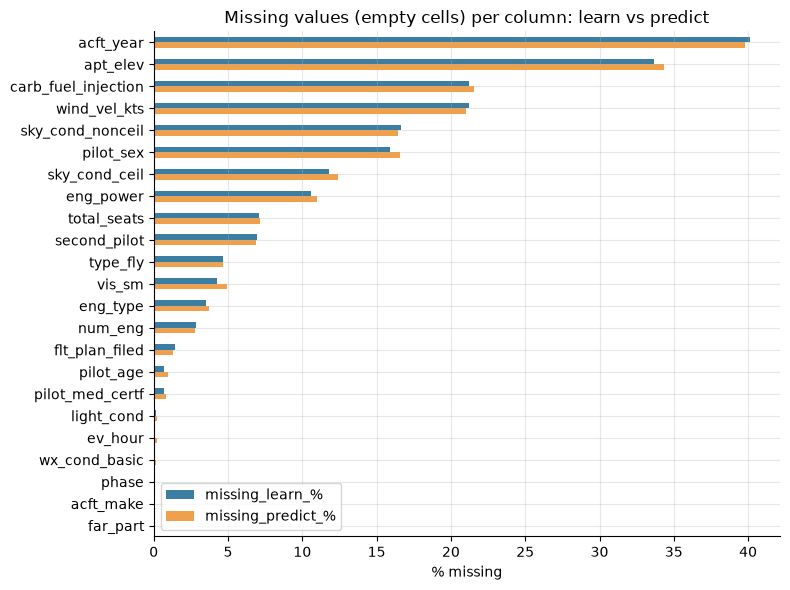

,missing_learn_%,missing_predict_%
acft_year,40.14,39.81
apt_elev,33.64,34.37
carb_fuel_injection,21.25,21.53
wind_vel_kts,21.22,21.04
sky_cond_nonceil,16.61,16.42
pilot_sex,15.88,16.58
sky_cond_ceil,11.79,12.39
eng_power,10.61,11.02
total_seats,7.10,7.18
second_pilot,6.97,6.86


In [64]:
miss = pd.DataFrame({
    "missing_learn_%": learn.drop(columns="fatal").isna().mean() * 100,
    "missing_predict_%": predict.isna().mean() * 100,
}).round(2)
miss = miss[miss.max(axis=1) > 0].sort_values("missing_learn_%", ascending=False)
print(f"{len(miss)} of 40 features have missing values")

ax = miss.plot.barh(figsize=(8, 6), color=["#3b7ea1", "#f0a04b"])
ax.invert_yaxis(); ax.set_xlabel("% missing"); ax.set_title("Missing values (empty cells) per column: learn vs predict")
plt.tight_layout(); plt.show()
miss

- **23 of the 40 features** have empty cells, and 86% of the rows have at least one missing value, so dropping rows with NaN is not an option: we would lose almost all the data.
- Missingness comes in three levels:
  - **heavy:** `acft_year` (~40%), `apt_elev` (~34%), `wind_vel_kts`, `carb_fuel_injection` (~21%)
  - **medium:** `sky_cond_nonceil`, `pilot_sex`, `sky_cond_ceil`, `eng_power` (10–17%)
  - **light:** the rest (< 8%)
- learn and predict have almost the same missing rates, so the data was collected the same way. Whatever strategy we choose will behave the same on `predict`.
- As we will see later many columns have missing values as `0` instead of Nan, this is a problem that will be needed to take care of.

**→ NB1:** a strategy per column (median/mode imputation, a `"MISSING"` category for categoricals, or missing indicators), fitted on the training folds only.

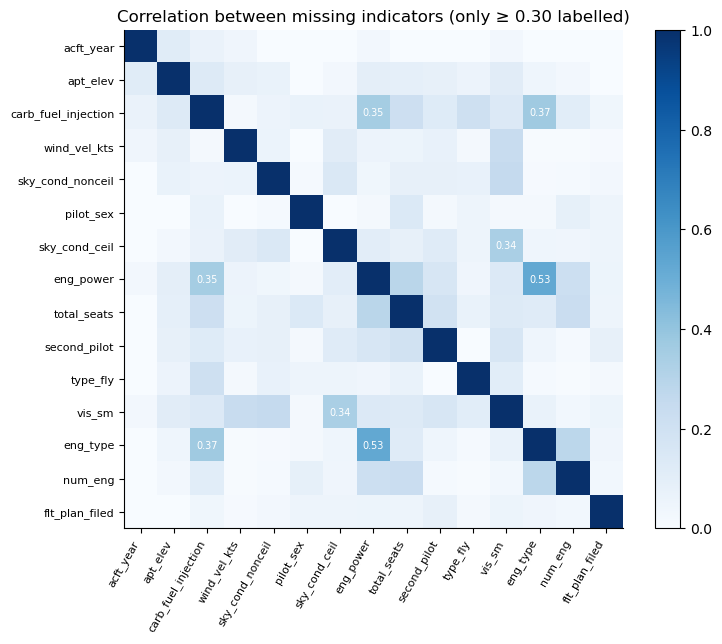

most related missing pairs:
 eng_power            eng_type       0.53
carb_fuel_injection  eng_type       0.37
                     eng_power      0.35
sky_cond_ceil        vis_sm         0.34
eng_power            total_seats    0.29
eng_type             num_eng        0.28
sky_cond_nonceil     vis_sm         0.25
wind_vel_kts         vis_sm         0.24


In [10]:
# Do columns tend to be missing on the same rows? Correlation between missing indicators.
cols = miss.index[miss["missing_learn_%"] >= 1]
M = learn[cols].isna().astype(int).corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8); ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        if i != j and M.iloc[i, j] >= 0.3:
            ax.text(j, i, f"{M.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white")
plt.colorbar(im); ax.set_title("Correlation between missing indicators (only ≥ 0.30 labelled)")
plt.tight_layout(); plt.show()

pairs = M.where(np.triu(np.ones(M.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("most related missing pairs:\n", pairs.head(8).round(2).to_string())

Missing values are not scattered at random: they come in blocks that share a source.
- **Engine block** (`eng_type`, `eng_power`, `carb_fuel_injection`, `num_eng`, and `total_seats` to a lesser extent): the clearest group (correlations 0.3–0.5), so the engine record tends to be missing as a whole.
- **Weather block:** `vis_sm` goes missing together with `sky_cond_ceil`, `sky_cond_nonceil` and `wind_vel_kts` (0.25–0.35): an incomplete weather report.
- The correlations are moderate, not 1: the blocks overlap without being all-or-nothing.
- `acft_year` is mostly missing for a different reason, the accident year (shown in Part 4).

**→ NB1:** impute related columns consistently (e.g. one `engine_info_missing` flag instead of four), and prefer models that handle missingness well (tree-based) or add indicators.

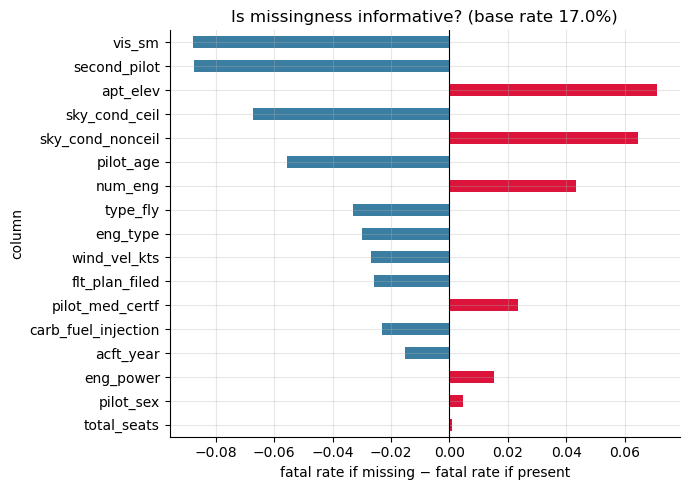

,n_missing,fatal_if_missing,fatal_if_present,difference
column,,,,
vis_sm,721,0.086,0.174,-0.088
second_pilot,1184,0.089,0.176,-0.088
apt_elev,5712,0.217,0.146,0.071
sky_cond_ceil,2002,0.111,0.178,-0.067
sky_cond_nonceil,2821,0.224,0.159,0.065
pilot_age,122,0.115,0.171,-0.056
num_eng,485,0.212,0.169,0.043
type_fly,787,0.139,0.172,-0.033
eng_type,602,0.141,0.171,-0.030


In [11]:
# Is "missing" informative about the target? Fatal rate when the column is missing vs present (n >= 30 only).
rows = []
for c in miss.index:
    m = learn[c].isna()
    if m.sum() >= 30:
        rows.append((c, m.sum(), learn.loc[m, "fatal"].mean(), learn.loc[~m, "fatal"].mean()))
mt = pd.DataFrame(rows, columns=["column", "n_missing", "fatal_if_missing", "fatal_if_present"]).set_index("column")
mt["difference"] = mt.fatal_if_missing - mt.fatal_if_present
mt = mt.sort_values("difference", key=abs, ascending=False)

ax = mt["difference"].plot.barh(figsize=(7, 5), color=np.where(mt["difference"] > 0, "crimson", "#3b7ea1"))
ax.invert_yaxis(); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("fatal rate if missing − fatal rate if present"); ax.set_title(f"Is missingness informative? (base rate {BASE:.1%})")
plt.tight_layout(); plt.show()
mt.round(3)

We decided to only analyze rows with at least 30 missing values, as less than this can be considered noise, the rows are split into two groups:
    rows where the column is empty
    rows where it has a value

Then it computes the fatal rate in each group and plots the difference: fatal rate if missing − fatal rate if present.
- Red bar (positive): accidents where this column is missing are more often fatal than the others.
- Blue bar (negative): accidents where it's missing are less often fatal.
- Bar near 0: missing or not makes no difference. The value is "missing at random" with respect to the target.

For several columns the fact that a value is missing is itself a signal:
  - When `apt_elev` or `sky_cond_nonceil` is missing, the fatal rate is higher (~22% vs ~15%). A plausible story: crashes far from an airport, or with poorly documented conditions.


If we just impute the media this information will be lost, for **NB1** we should add a missing indicator feature, next to the imputed values.

## 1.4 Hidden missing values and inconsistent codes
The brief warns about *"odd codes, impossible values, inconsistent spellings"*. Here we look for **zeros that really mean "not recorded"**, and for categories spelled in more than one way. The details are studied in each part; this is the overview.

First lets check which columns have zeros, and from those we will only evaluate the ones where the 0 is an actual integer, as in some it is used as a true or false.

In [66]:
has0 = learn.loc[:, (learn == 0).any(axis=0)]
has0

,ev_hour,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,apt_dist,apt_elev,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_power,pilot_age,fatal
0,19.0,0,10.0,59,15.0,49,38,7.0,0,30.06,0,NaN,0,1.0,2.0,1956.0,NaN,71.0,0
1,17.0,0,5.0,70,21.1,56,0,3.0,0,29.91,9,629.0,0,1.0,2.0,NaN,108.0,17.0,1
2,22.0,0,10.0,80,26.7,73,0,10.0,17,30.06,0,NaN,0,1.0,2.0,NaN,84.0,46.0,0
3,0.0,10208,10.0,80,26.7,33,261,6.0,0,30.07,0,NaN,1,1.0,4.0,1976.0,150.0,31.0,1
4,1.0,0,10.0,62,16.7,36,261,13.0,18,29.90,0,3092.0,0,1.0,4.0,NaN,174.0,68.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16974,18.0,7055,10.0,67,19.4,36,251,14.0,20,29.93,0,1141.0,0,1.0,2.0,2008.0,119.0,65.0,0
16975,21.0,7987,10.0,36,2.2,27,309,18.0,30,29.67,1,1454.0,1,2.0,8.0,1984.0,422.0,63.0,0
16976,20.0,879,NaN,17,-8.3,11,117,5.0,0,30.27,0,1630.0,1,2.0,6.0,1972.0,370.0,68.0,0
16977,2.0,14178,10.0,57,13.9,0,304,NaN,0,0.00,0,NaN,0,1.0,4.0,NaN,268.0,44.0,0


In [12]:
zero_cols = ["wx_temp", "wx_dew_pt", "altimeter", "wind_dir_deg", "sky_ceil_ht", "gust_kts",
             "apt_dist", "eng_power", "total_seats", "pilot_age", "acft_year"]
plausible = {  # is 0 a physically possible value?
    "wx_temp": "rare (0 °F) but possible", "wx_dew_pt": "rare but possible", "altimeter": "IMPOSSIBLE",
    "wind_dir_deg": "possible only with calm wind", "sky_ceil_ht": "means 'no ceiling'?",
    "gust_kts": "yes, no gusts", "apt_dist": "yes, at the airport", "eng_power": "IMPOSSIBLE (powered)",
    "total_seats": "only gliders/balloons?", "pilot_age": "IMPOSSIBLE", "acft_year": "IMPOSSIBLE"}
z = pd.DataFrame({
    "zeros_learn": [(learn[c] == 0).sum() for c in zero_cols],
    "zeros_%": [round((learn[c] == 0).mean() * 100, 1) for c in zero_cols],
    "zeros_predict_%": [round((predict[c] == 0).mean() * 100, 1) for c in zero_cols],
    "fatal_if_0": [learn.loc[learn[c] == 0, "fatal"].mean() for c in zero_cols],
    "fatal_if_not_0": [learn.loc[learn[c] != 0, "fatal"].mean() for c in zero_cols],
    "is 0 plausible?": [plausible[c] for c in zero_cols],
}, index=zero_cols).round(3)
z

,zeros_learn,zeros_%,zeros_predict_%,fatal_if_0,fatal_if_not_0,is 0 plausible?
wx_temp,855,5.0,5.0,0.067,0.176,rare (0 °F) but possible
wx_dew_pt,1639,9.7,9.9,0.057,0.182,rare but possible
altimeter,1510,8.9,8.7,0.056,0.181,IMPOSSIBLE
wind_dir_deg,4387,25.8,26.1,0.148,0.178,possible only with calm wind
sky_ceil_ht,12834,75.6,76.0,0.145,0.247,means 'no ceiling'?
gust_kts,14358,84.6,84.0,0.171,0.163,"yes, no gusts"
apt_dist,13119,77.3,77.6,0.141,0.268,"yes, at the airport"
eng_power,171,1.0,0.8,0.129,0.171,IMPOSSIBLE (powered)
total_seats,37,0.2,0.1,0.027,0.170,only gliders/balloons?
pilot_age,4,0.0,0.0,0.000,0.170,IMPOSSIBLE


In [13]:
# The weather zeros come together: is it one missing weather observation?
w0 = (learn.wx_temp == 0) & (learn.wx_dew_pt == 0) & (learn.altimeter == 0)
print(f"rows with temp = dew point = altimeter = 0: {w0.sum()} ({w0.mean():.1%}) · in predict: {((predict.wx_temp == 0) & (predict.wx_dew_pt == 0) & (predict.altimeter == 0)).mean():.1%}")
print(f"fatal rate in those rows: {learn.loc[w0, 'fatal'].mean():.1%} vs {learn.loc[~w0, 'fatal'].mean():.1%} elsewhere")
print(f"wind_dir_deg = 0 and wind_vel_kts empty: {((learn.wind_dir_deg == 0) & learn.wind_vel_kts.isna()).sum()} of {(learn.wind_dir_deg == 0).sum()} zero directions")

print("\ngust_ind vs gust_kts > 0 (does the indicator agree with the speed?):")
print(pd.crosstab(learn.gust_ind, learn.gust_kts > 0, rownames=["gust_ind"], colnames=["gust_kts > 0"]))

rows with temp = dew point = altimeter = 0: 771 (4.5%) · in predict: 4.5%
fatal rate in those rows: 6.1% vs 17.5% elsewhere
wind_dir_deg = 0 and wind_vel_kts empty: 3543 of 4387 zero directions

gust_ind vs gust_kts > 0 (does the indicator agree with the speed?):
gust_kts > 0  False  True 
gust_ind                  
F              3429   2616
T             10929      5


- Weather. In 771 rows (4.5%, the same share in `predict`) temperature, dew point and altimeter are all 0. An altimeter of 0 inHg is impossible, so these rows are a whole missing weather observation coded as zeros. Their fatal rate is very different from the others (~6% vs ~18%), so the missingness is informative. Likewise, almost every `wind_dir_deg = 0` comes with an empty `wind_vel_kts`: it is "not recorded", not "north".
- `gust_ind` seems to be inverted: `T` almost never comes with a gust speed > 0, while `F` often does. Either the code means the opposite of what we expect, or it is broken. 

**→ NB1:** replace the impossible zeros with NaN **before** imputation (otherwise medians and means are biased); add a `weather_obs_missing` flag; decide `gust_ind` together with Part 3.

In [14]:
# Categories spelled in more than one way (same value, different case or spaces)
rows = []
for c in learn.select_dtypes("object").columns.drop("row_id"):
    s = pd.concat([learn[c], predict[c]]).dropna().astype(str)
    raw, norm = s.nunique(), s.str.strip().str.upper().nunique()
    if raw != norm:
        rows.append((c, raw, norm, (s != s.str.strip().str.upper()).mean() * 100))
pd.DataFrame(rows, columns=["column", "distinct_raw", "distinct_after_upper_strip", "% rows affected"]).round(1)

,column,distinct_raw,distinct_after_upper_strip,% rows affected
0,acft_category,20,11,24.8
1,homebuilt,4,2,25.2
2,second_pilot,4,2,25.2


A few text columns contain the same category written in different cases (e.g. `AIR`/`air`, `Y`/`y`, `N`/`n`), in about a quarter of their rows and in both files. A model would see them as different levels and split the information. Part 4 shows that lowercase carries no information (same fatal rate). `acft_make` also has spelling variants beyond case (Part 4).

**→ NB1:** one cleaning function (strip + upper) applied to every text column of `learn` and `predict`.

## 1.5 learn vs predict: do they come from the same distribution?
If `predict` looked very different from `learn` (other years, other kinds of aircraft), a model validated on `learn` would perform worse on Kaggle than expected.

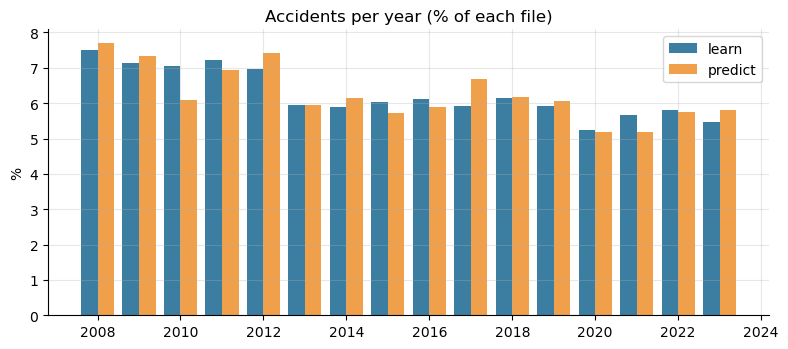

share of accidents in 2008-2013 · learn: 41.8% · predict: 41.4%


In [15]:
# ev_year in both files (Part 4 needs this: is the missing acft_year of 2008-2013 also in predict?)
yl = learn.ev_year.value_counts(normalize=True).sort_index()
yp = predict.ev_year.value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
w = .4
ax.bar(yl.index - w / 2, yl.values * 100, w, label="learn", color="#3b7ea1")
ax.bar(yp.index + w / 2, yp.values * 100, w, label="predict", color="#f0a04b")
ax.set_title("Accidents per year (% of each file)"); ax.set_ylabel("%"); ax.legend()
plt.tight_layout(); plt.show()
print(f"share of accidents in 2008-2013 · learn: {(learn.ev_year <= 2013).mean():.1%} · predict: {(predict.ev_year <= 2013).mean():.1%}")

In [16]:
# Numeric columns: compare mean and median; standardised mean difference (SMD) = |mean_l - mean_p| / std_l
num = learn.select_dtypes("number").columns.drop("fatal")
cmp_num = pd.DataFrame({
    "mean_learn": learn[num].mean(), "mean_predict": predict[num].mean(),
    "median_learn": learn[num].median(), "median_predict": predict[num].median(),
})
cmp_num["SMD"] = ((cmp_num.mean_learn - cmp_num.mean_predict).abs() / learn[num].std())
display(cmp_num.sort_values("SMD", ascending=False).round(3))

# Categorical columns: total variation distance between the two frequency distributions (0 = identical, 1 = disjoint)
cat = learn.select_dtypes("object").columns.drop("row_id")
tvd = {c: 0.5 * (learn[c].value_counts(normalize=True, dropna=False)
                 .sub(predict[c].value_counts(normalize=True, dropna=False), fill_value=0).abs().sum()) for c in cat}
pd.Series(tvd, name="TVD learn vs predict").sort_values(ascending=False).round(3).to_frame()

,mean_learn,mean_predict,median_learn,median_predict,SMD
eng_power,695.357,521.758,189.00,189.0,0.038
sky_ceil_ht,1575.381,1441.016,0.00,0.0,0.030
gust_kts,3.152,3.417,0.00,0.0,0.024
total_seats,6.633,4.974,4.00,4.0,0.021
wx_temp,63.992,63.339,69.00,69.0,0.020
wx_temp_c,17.772,17.410,20.60,20.6,0.020
ifr_equipped_cert,0.170,0.178,0.00,0.0,0.020
wind_dir_deg,142.211,140.130,146.00,145.0,0.018
ev_hour,15.687,15.608,17.00,17.0,0.012
vis_sm,10.698,10.063,10.00,10.0,0.012


,TVD learn vs predict
acft_make,0.217
phase,0.021
carb_fuel_injection,0.015
type_fly,0.014
acft_category,0.013
sky_cond_ceil,0.012
ev_dow,0.012
light_cond,0.010
flt_plan_filed,0.010
homebuilt,0.009



- **Years:** `predict` covers the same 2008–2023 period with the same proportions, including the early years where `acft_year` is almost always missing. So an `acft_year_missing` indicator behaves the same in `predict`(answer to Part 4's question).
- **Numeric columns:** every standardised mean difference is below 0.04 (0.1 is a common threshold for a meaningful shift). The means of `eng_power` and `total_seats` differ a bit because of a few huge outliers (Part 4); the medians are identical.
- **Categorical columns:** every distance is ≤ 0.02 except `acft_make` (0.22), which is expected with ~2,900 rare values: many makes appear in only one of the files (Part 4: ~13% of `predict` rows have a make never seen in `learn`).
- **Conclusion:** `predict` looks like a random sample from the same population as `learn`. A stratified cross-validation on `learn` should give a fair estimate of the Kaggle score.

**→ NB1:** use stratified K-fold CV as the main evaluation; handle categories unseen in training (`handle_unknown`).

## 1.6 Correlations between numeric features
Spearman (rank) correlation, because many columns are skewed and full of outliers. Note: this uses the raw data, so hidden zeros (1.4) still distort some values.

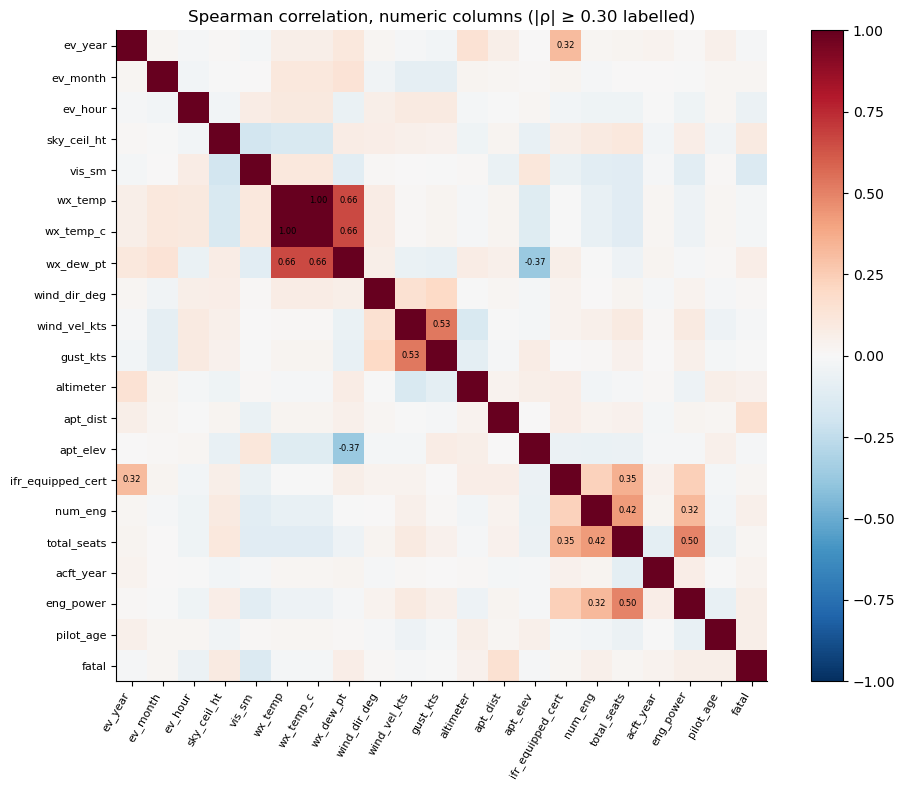

strongest pairs between features:
 wx_temp            wx_temp_c      1.000
wx_temp_c          wx_dew_pt      0.661
wx_temp            wx_dew_pt      0.661
wind_vel_kts       gust_kts       0.526
total_seats        eng_power      0.495
num_eng            total_seats    0.422
wx_dew_pt          apt_elev      -0.370
ifr_equipped_cert  total_seats    0.352

strongest correlations with fatal:
 apt_dist       0.149
vis_sm        -0.135
sky_ceil_ht    0.090
wx_dew_pt      0.066
pilot_age      0.059
eng_power      0.056
ev_hour       -0.055
num_eng        0.052


In [17]:
num_all = learn.select_dtypes("number").columns
C = learn[num_all].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(C))); ax.set_xticklabels(C.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(C))); ax.set_yticklabels(C.columns, fontsize=8); ax.grid(False)
for i in range(len(C)):
    for j in range(len(C)):
        if i != j and abs(C.iloc[i, j]) >= 0.3:
            ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im); ax.set_title("Spearman correlation, numeric columns (|ρ| ≥ 0.30 labelled)")
plt.tight_layout(); plt.show()

pairs = C.where(np.triu(np.ones(C.shape), 1).astype(bool)).stack()
print("strongest pairs between features:\n", pairs.drop(index="fatal", level=1, errors="ignore")
      .sort_values(key=abs, ascending=False).head(8).round(3).to_string())
print("\nstrongest correlations with fatal:\n", C["fatal"].drop("fatal").sort_values(key=abs, ascending=False).head(8).round(3).to_string())


**Redundant pairs:**
  - `wx_temp` / `wx_temp_c` (ρ = 1, already known).
  - `wx_temp` and `wx_dew_pt` (~0.66): partly physics, partly the shared zeros.
  - `wind_vel_kts` and `gust_kts` (~0.53).
  - The aircraft-size group `total_seats`, `eng_power`, `num_eng`, `ifr_equipped_cert` (0.2–0.5), consistent with Part 4.

**With the target, every single numeric correlation is weak** (|ρ| ≤ ~0.15). The strongest are `apt_dist` (further from an airport → more fatal), `vis_sm` (lower visibility → more fatal) and `sky_ceil_ht`.
  - No single numeric feature separates the classes. Performance will come from **combining** features, including categoricals such as `phase` and `light_cond`, which this matrix does not show.
  - Non-linear models (trees, boosting) are likely to do better than a plain linear model.

**→ NB1:** drop `wx_temp_c`; watch multicollinearity if a linear model is used.

# ━━━━━━━━━━ PART 4 · Aircraft and engine (Person 4) ━━━━━━━━━━

Columns covered (11): `acft_category`, `homebuilt`, `fixed_retractable`, `acft_make`, `ifr_equipped_cert`, `num_eng`, `total_seats`, `acft_year`, `eng_type`, `carb_fuel_injection`, `eng_power`.

NB0 does not change the data and does not train models. When a cleaning step is needed just to *look* at something (for example upper-casing a category), it is done on a throw-away copy, and the real cleaning is listed as a decision for NB1 at the end of this part.

In [18]:
# Only needed by Part 4
import re

GROUP = ["acft_category", "homebuilt", "fixed_retractable", "acft_make", "ifr_equipped_cert",
         "num_eng", "total_seats", "acft_year", "eng_type", "carb_fuel_injection", "eng_power"]

## Part 4 · 1. Overview of the group

**What we do:** data types, missing values and cardinality of the 11 columns, in `learn` and in `predict`.

In [19]:
ov = pd.DataFrame({
    "dtype": learn[GROUP].dtypes.astype(str),
    "missing_learn_%": (learn[GROUP].isna().mean() * 100).round(1),
    "missing_predict_%": (predict[GROUP].isna().mean() * 100).round(1),
    "n_unique": learn[GROUP].nunique(),
})
ov

,dtype,missing_learn_%,missing_predict_%,n_unique
acft_category,object,0.0,0.0,19
homebuilt,object,0.0,0.0,4
fixed_retractable,object,0.0,0.0,2
acft_make,object,0.0,0.0,2914
ifr_equipped_cert,int64,0.0,0.0,2
num_eng,float64,2.9,2.8,7
total_seats,float64,7.1,7.2,135
acft_year,float64,40.1,39.8,102
eng_type,object,3.5,3.7,11
carb_fuel_injection,object,21.2,21.5,2


**Interpretation.**
- Missingness is very uneven: `acft_year` (40%), `carb_fuel_injection` (21%), `eng_power` (11%), `total_seats` (7%), `eng_type` (3.5%), `num_eng` (2.9%). The other six columns are complete. `learn` and `predict` have similar missing rates, which is good (no shift in how the data was collected).
- `acft_make` has 2,914 distinct values: it is a free-text field, not a real category (section 3).
- `num_eng`, `total_seats`, `acft_year` and `eng_power` are floats only because of the NaNs.

**→ NB1:** missing values need an explicit strategy per column (imputation and/or a missing indicator). Section 6 shows that the 40% in `acft_year` is not random.

## Part 4 · 2. Inconsistent case: `acft_category` and `homebuilt`

**What we do:** the brief warns that `AIR`/`air`, `HELI`/`heli` and `Y`/`y` coexist. We check how widespread it is (also in `predict`) and whether the lowercase rows mean something different. We work on a copy `A`; `learn` is untouched.

In [20]:
for col in ["acft_category", "homebuilt"]:
    print(pd.concat({"learn": learn[col].value_counts(), "predict": predict[col].value_counts()}, axis=1)
            .fillna(0).astype(int).sort_values("learn", ascending=False), "\n")

print("rows with lowercase acft_category:", (learn.acft_category.str.islower()).sum(),
      f"({learn.acft_category.str.islower().mean():.1%})")
print("rows with lowercase homebuilt:    ", (learn.homebuilt.str.islower()).sum(),
      f"({learn.homebuilt.str.islower().mean():.1%})")

               learn  predict
acft_category                
AIR            10899     2746
air             3655      885
HELI            1285      325
heli             382       85
GLI              208       61
BALL             105       21
WSFT              98       25
GYRO              90       18
gli               64       30
PPAR              53       13
wsft              40       10
ball              31        9
gyro              29       10
ppar              19        3
ULTR              13        2
ultr               4        0
PLFT               2        1
RCKT               1        0
BLIM               1        0
plft               0        1 

           learn  predict
homebuilt                
N          10894     2760
n           3707      912
Y           1797      426
y            581      147 

rows with lowercase acft_category: 4224 (24.9%)
rows with lowercase homebuilt:     4288 (25.3%)


Fatal rate: uppercase vs lowercase spelling (same category?)
            mean   size
was_lower              
False      0.171  12755
True       0.168   4224 



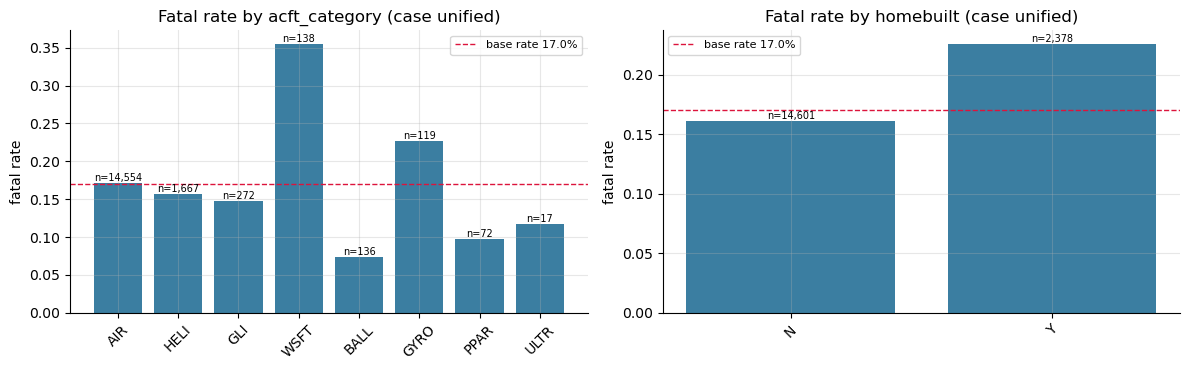

In [21]:
A = learn.copy()                                  # throw-away copy for analysis only
A["acft_category_u"] = A["acft_category"].str.upper()
A["homebuilt_u"] = A["homebuilt"].str.upper()
A["was_lower"] = A["acft_category"].str.islower()

print("Fatal rate: uppercase vs lowercase spelling (same category?)")
print(A.groupby("was_lower")["fatal"].agg(["mean", "size"]).round(3), "\n")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plot_cat_vs_target(A, "acft_category_u", min_n=15, ax=ax[0], title="Fatal rate by acft_category (case unified)")
plot_cat_vs_target(A, "homebuilt_u", min_n=15, ax=ax[1], title="Fatal rate by homebuilt (case unified)")
plt.tight_layout(); plt.show()

**Interpretation.**
- About a quarter of the rows are lowercase (`air` 3,655 vs `AIR` 10,899, `n` 3,707 vs `N` 10,894...) and `predict` has the same pattern, so a model fed the raw strings would treat `AIR` and `air` as different levels.
- Lowercase is **noise in the spelling**, not information: the fatal rate is about the same in both groups. After unifying, the categories behave sensibly: airplanes and helicopters are close to the base rate (17%/16%), weight-shift (`WSFT`) is much riskier (36%), balloons and powered parachutes are safer (7–10%). Homebuilt aircraft are more fatal (23% vs 16%).
- Several categories are tiny (`PLFT` 2, `RCKT` 1, `BLIM` 1, `ULTR` 17): their rates are meaningless.

**→ NB1:** upper-case both columns (and apply the same function to `predict`); group categories with fewer than about 30 rows into `OTHER`.

## Part 4 · 3. Aircraft make: `acft_make`

**What we do:** study the cardinality, the spelling variants and the rare makes. Normalisation here (upper case, remove punctuation and company suffixes) is only used to *measure* how much of the 2,914 distinct values are really the same make.

In [22]:
def norm_make(s):
    s = str(s).upper()
    s = re.sub(r"[^A-Z0-9 ]", "", s)
    s = re.sub(r"\b(INC|CORP|CORPORATION|CO|COMPANY|LLC|LTD|THE)\b", "", s)
    return re.sub(r"\s+", " ", s).strip()

A["make_n"] = A["acft_make"].map(norm_make)
P = predict.copy(); P["make_n"] = P["acft_make"].map(norm_make)

vc = A["make_n"].value_counts()
print(f"distinct raw values: {learn.acft_make.nunique():,} · after light normalisation: {A.make_n.nunique():,}")
print(f"makes with >=100 rows: {(vc >= 100).sum()} · >=30 rows: {(vc >= 30).sum()} · <=5 rows: {(vc <= 5).sum():,} · exactly 1 row: {(vc == 1).sum():,}")
print(f"share of rows covered by top 10 / 50 / 200 makes: "
      f"{vc.head(10).sum()/len(A):.0%} / {vc.head(50).sum()/len(A):.0%} / {vc.head(200).sum()/len(A):.0%}")
print(f"share of rows that belong to makes with <=5 rows: {vc[vc <= 5].sum()/len(A):.1%}")
print(f"share of predict rows whose (normalised) make never appears in learn: {(~P.make_n.isin(A.make_n)).mean():.1%}")
print("\nSpelling variants, e.g. ROBINSON and CESSNA:")
print(learn[learn.acft_make.str.upper().str.contains("ROBINSON HELI|^ROBINSON$", na=False)].acft_make.value_counts().head(6).to_string())
print(learn[learn.acft_make.str.upper().str.contains("CESSNA", na=False)].acft_make.value_counts().head(5).to_string())

distinct raw values: 2,914 · after light normalisation: 2,803
makes with >=100 rows: 17 · >=30 rows: 50 · <=5 rows: 2,614 · exactly 1 row: 2,299
share of rows covered by top 10 / 50 / 200 makes: 56% / 71% / 82%
share of rows that belong to makes with <=5 rows: 18.6%
share of predict rows whose (normalised) make never appears in learn: 13.2%

Spelling variants, e.g. ROBINSON and CESSNA:
acft_make
ROBINSON HELICOPTER            194
ROBINSON HELICOPTER COMPANY    155
ROBINSON                       143
ROBINSON HELICOPTER CO          15
acft_make
CESSNA                   4248
CESSNA AIRCRAFT CO         21
CESSNA ECTOR                4
CESSNA/AIR REPAIR INC       2
POOL CESSNA                 1


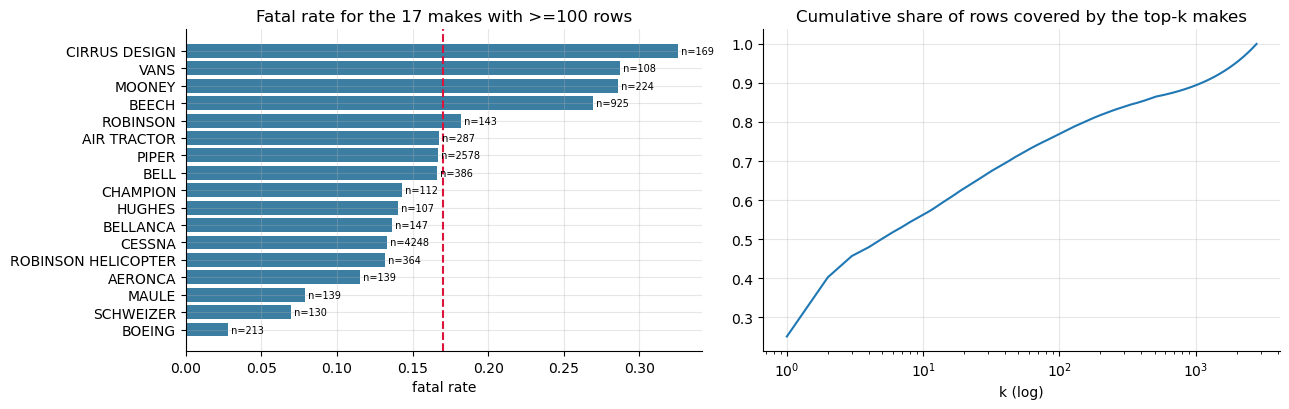

fatal rate, makes with <=5 rows vs the rest: 0.21 vs 0.161


In [23]:
top = vc[vc >= 100].index
g = (A[A.make_n.isin(top)].groupby("make_n")["fatal"].agg(rate="mean", n="size").sort_values("rate"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(g.index, g["rate"], color="#3b7ea1"); ax[0].axvline(BASE, color="crimson", ls="--")
for i, (r, n) in enumerate(zip(g["rate"], g["n"])): ax[0].text(r, i, f" n={n}", va="center", fontsize=7)
ax[0].set_title("Fatal rate for the 17 makes with >=100 rows"); ax[0].set_xlabel("fatal rate")

rank = np.arange(1, len(vc) + 1)
ax[1].plot(rank, vc.values.cumsum() / vc.sum()); ax[1].set_xscale("log")
ax[1].set_title("Cumulative share of rows covered by the top-k makes"); ax[1].set_xlabel("k (log)")
plt.tight_layout(); plt.show()

rare = A["make_n"].map(vc) <= 5
print("fatal rate, makes with <=5 rows vs the rest:", round(A[rare].fatal.mean(), 3), "vs", round(A[~rare].fatal.mean(), 3))

**Interpretation.**
- Light normalisation only reduces 2,914 values to ~2,800 and merges the big duplicates (`ROBINSON` vs `ROBINSON HELICOPTER`, `CESSNA` vs `CESSNA AIRCRAFT CO`). The remaining ones are mostly one-off names (homebuilders, individuals, old manufacturers): ~2,300 makes appear only once.
- It is a long-tail variable: only 17 makes have ≥ 100 rows (top 10 ≈ 56% of the rows, top 50 ≈ 71%) while ~19% of the rows belong to makes with ≤ 5 rows.
- About **13% of `predict` rows have a make that never appears in `learn`**, so the model will have to deal with unseen categories. A plain one-hot over all makes would be huge and mostly useless.
- There *is* signal in the big makes: Boeing 3%, Schweizer 7%, Maule 8% versus Cirrus 33%, Vans 29%, Mooney 29%, Beech 27% (base rate 17%). Rare makes are riskier than average (21% vs 16%), probably because they are homebuilt/experimental or old aircraft.

**→ NB1:** (1) normalise the text; (2) keep the top ~30–50 makes and group the rest as `OTHER` (or use frequency encoding / target encoding **inside** the cross-validation to avoid leakage); (3) add a `make_is_rare` flag; (4) make sure the encoding handles makes unseen in `learn`.

## Part 4 · 4. Other categorical columns versus the target

**What we do:** `fixed_retractable`, `ifr_equipped_cert`, `num_eng`, `eng_type` and `carb_fuel_injection` against `fatal`. Missing values are kept as their own group (`dropna=False`) so we can see if missing is informative.

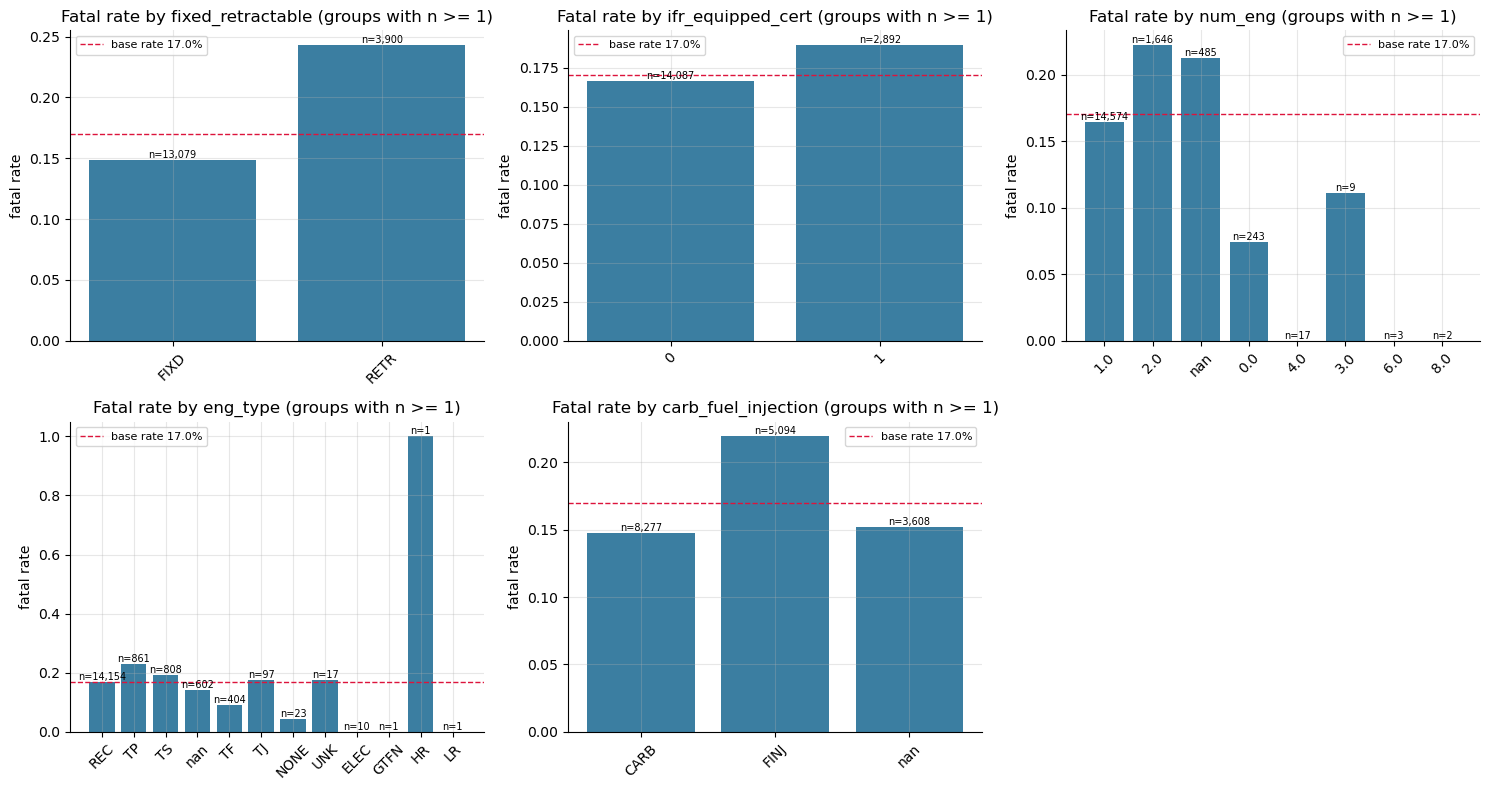

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
plot_cat_vs_target(A, "fixed_retractable", min_n=1, ax=ax[0, 0])
plot_cat_vs_target(A, "ifr_equipped_cert", min_n=1, ax=ax[0, 1])
plot_cat_vs_target(A, "num_eng", min_n=1, ax=ax[0, 2])
plot_cat_vs_target(A, "eng_type", min_n=1, ax=ax[1, 0])
plot_cat_vs_target(A, "carb_fuel_injection", min_n=1, ax=ax[1, 1])
ax[1, 2].axis("off")
plt.tight_layout(); plt.show()

In [25]:
print("eng_type vs carb_fuel_injection (counts):")
print(pd.crosstab(A.eng_type.fillna("NaN"), A.carb_fuel_injection.fillna("NaN")))
print("\nnum_eng == 0 by aircraft category:")
print(A[A.num_eng == 0].acft_category_u.value_counts())

eng_type vs carb_fuel_injection (counts):
carb_fuel_injection  CARB  FINJ   NaN
eng_type                             
ELEC                    0     0    10
GTFN                    0     0     1
HR                      0     0     1
LR                      0     0     1
NONE                    0     0    23
NaN                     1     0   601
REC                  8270  4595  1289
TF                      1    62   341
TJ                      0    22    75
TP                      0   199   662
TS                      2   213   593
UNK                     3     3    11

num_eng == 0 by aircraft category:
acft_category_u
GLI     168
BALL     73
AIR       2
Name: count, dtype: int64


**Interpretation.**
- **Retractable gear** is clearly riskier (24% vs 15%). Faster, more complex aircraft: a strong, simple feature.
- `num_eng`: twins (2) are riskier (22%) than singles (16.5%). `num_eng = 0` (243 rows, 7% fatal) are gliders and balloons, so it is a valid value, not an error. 3, 4, 6, 8 engines are almost never seen (≤ 17 rows).
- `eng_type`: `REC` (piston) is 83% of the data. `TP` turboprop has the highest rate (23%); `TF` turbofan is the lowest (9%, large airliners). Rare codes (`HR`, `GTFN`, `LR`, `ELEC`, `NONE`, `UNK`) have ≤ 23 rows.
- `carb_fuel_injection`: fuel-injected is riskier (22% vs 15%). But `NaN` is **structural**: it only makes sense for piston engines, and it is missing for 73–84% of turbine engines and 100% of electric/no-engine. That is "not applicable", not "unknown". Within `REC` it is missing for only 9%.
- `ifr_equipped_cert` has a weak effect (19% vs 17%).

**→ NB1:** keep `NaN` in `carb_fuel_injection` as an explicit category (`NOT_APPLICABLE`/`UNKNOWN`), group rare `eng_type` codes, cap `num_eng` at 3+ (or treat as category). Question: `retractable`, `eng_type` and `num_eng` are probably correlated (powerful complex aircraft): check redundancy during feature selection.

## Part 4 · 5. The column whose unit changes: `eng_power`

**What we do:** the dictionary says `eng_power` is horsepower for piston and turboprop engines and pounds of thrust for jets. We plot it split by `eng_type` and look at zeros and extremes.

            count     mean      std      min      25%      50%      75%       max
eng_type                                                                         
ELEC          4.0     27.0     18.0      5.0     20.0     27.0     34.0      50.0
GTFN          1.0   3399.0      NaN   3399.0   3399.0   3399.0   3399.0    3399.0
HR            1.0  59570.0      NaN  59570.0  59570.0  59570.0  59570.0   59570.0
REC       13217.0    202.0    154.0      0.0    132.0    179.0    252.0    3293.0
TF          334.0  17441.0  24197.0      0.0   3261.0   8926.0  23993.0  264190.0
TJ           87.0   9312.0  12840.0      0.0   2072.0   3424.0  10717.0   63837.0
TP          765.0    846.0    566.0      0.0    661.0    754.0    908.0   10378.0
TS          733.0    722.0   2797.0     91.0    413.0    519.0    707.0   75552.0
UNK           6.0    224.0     89.0    143.0    156.0    194.0    283.0     356.0


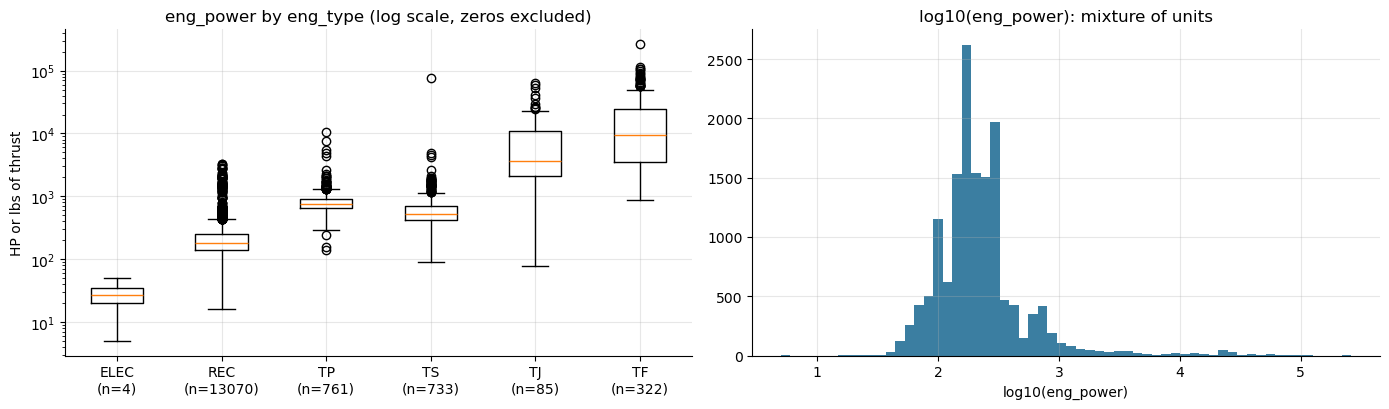


eng_power == 0: 171 rows · by eng_type:
eng_type
REC    147
TF      12
NaN      6
TP       4
TJ       2
Name: count, dtype: int64

lowest power among jets (lbs of thrust should be in the thousands):
[77.0, 82.0, 88.0, 93.0, 240.0]
piston (REC) engines above 1,500 HP: 39 → mostly large vintage aircraft

missing eng_power by eng_type (share):
eng_type
ELEC    0.60
LR      1.00
NONE    1.00
NaN     0.95
REC     0.07
TF      0.17
TJ      0.10
TP      0.11
TS      0.09
UNK     0.65
Name: eng_power, dtype: float64


In [26]:
order = ["ELEC", "REC", "TP", "TS", "TJ", "TF"]
print(A.groupby("eng_type")["eng_power"].describe().round(0).loc[lambda d: d["count"] > 0])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
data = [A.loc[(A.eng_type == t) & (A.eng_power > 0), "eng_power"] for t in order]
ax[0].boxplot(data, tick_labels=[f"{t}\n(n={len(d)})" for t, d in zip(order, data)], showfliers=True)
ax[0].set_yscale("log"); ax[0].set_title("eng_power by eng_type (log scale, zeros excluded)"); ax[0].set_ylabel("HP or lbs of thrust")
ax[1].hist(np.log10(A.loc[A.eng_power > 0, "eng_power"]), bins=60, color="#3b7ea1")
ax[1].set_title("log10(eng_power): mixture of units"); ax[1].set_xlabel("log10(eng_power)")
plt.tight_layout(); plt.show()

print("\neng_power == 0:", (A.eng_power == 0).sum(), "rows · by eng_type:")
print(A[A.eng_power == 0].eng_type.value_counts(dropna=False).head())
print("\nlowest power among jets (lbs of thrust should be in the thousands):")
print(A[A.eng_type.isin(["TF", "TJ"]) & (A.eng_power > 0)].eng_power.nsmallest(5).tolist())
print("piston (REC) engines above 1,500 HP:", ((A.eng_type == "REC") & (A.eng_power > 1500)).sum(), "→ mostly large vintage aircraft")
print("\nmissing eng_power by eng_type (share):")
print(A.eng_power.isna().groupby(A.eng_type.fillna("NaN")).mean().round(2).loc[lambda s: s > 0])

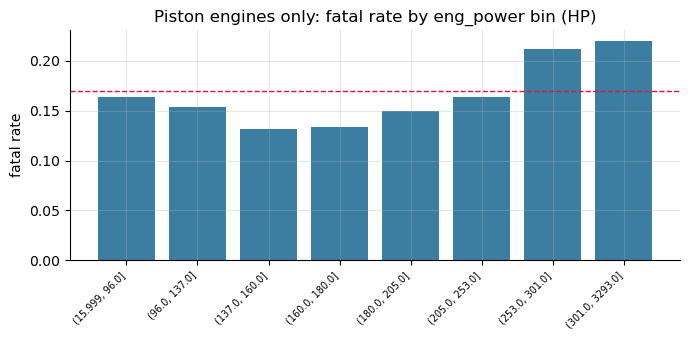

Fatal rate by eng_type, power==0 vs >0 (piston): {False: 0.169, True: 0.136}


In [27]:
# Does power matter inside each unit family? (fatal rate by quantile bin, piston only)
rec = A[(A.eng_type == "REC") & (A.eng_power > 0)]
plot_num_vs_target(rec, "eng_power", q=8, title="Piston engines only: fatal rate by eng_power bin (HP)")
plt.tight_layout(); plt.show()
print("Fatal rate by eng_type, power==0 vs >0 (piston):",
      A[A.eng_type == "REC"].groupby(A.eng_power.eq(0))["fatal"].mean().round(3).to_dict())

**Interpretation.**
- The unit problem is real and big: piston engines are around 100–300 (HP), turboprops ~750 HP, but turbofans have a median of ~8,900 and go up to 264,190 (lbs of thrust, with outliers that look like errors). The histogram in log scale is a mix of two populations. A single numeric `eng_power` makes a jet look 50× "more powerful" than a piston when it has nothing to do with it, and it would dominate any distance- or scale-based model (and the mean/std).
- `eng_power = 0` in 171 rows (147 of them piston): impossible, it is a missing-value code. A few jets have power < 1,000 (probably HP-style entries in the wrong unit).
- `eng_power` is missing together with `eng_type`: for rows where `eng_type` is `NaN` it is missing 95% of the time.
- Within piston engines, check the last plot: if the fatal rate changes across HP bins there is signal once the unit is homogeneous (this is the comparison that makes sense; mixing HP and lbs is not).

**→ NB1:** treat `eng_power = 0` as `NaN`; build `eng_power_hp` (piston/turboprop/turboshaft/electric) and `eng_thrust_lbs` (TF/TJ) as two separate features (or a log-transform *interacted* with engine family). Cap or winsorise extreme values. Question: impute power by median per `eng_type`, or only flag it?

## Part 4 · 6. Impossible values: `total_seats` and `acft_year`

**What we do:** look for values that cannot be true (`acft_year` after the accident year or absurdly old, odd seat counts) and understand why `acft_year` is missing 40% of the time.

In [28]:
print("=== total_seats ===")
print("seats == 0:", (A.total_seats == 0).sum(), " seats > 100:", (A.total_seats > 100).sum(), " max:", A.total_seats.max())
print(A.total_seats.describe().round(1).to_dict())
print("\nseats > 100: category / operation / fatal rate")
big = A[A.total_seats > 100]
print(big.acft_category_u.value_counts().to_dict(), big.far_part.value_counts().head(3).to_dict(), "fatal:", round(big.fatal.mean(), 3))
print("odd seat counts (3,5,7,9) vs even (2,4,6,8):", A.total_seats.isin([3, 5, 7, 9]).sum(), "vs", A.total_seats.isin([2, 4, 6, 8]).sum())
print("seats, median by category:", A.groupby("acft_category_u").total_seats.median().to_dict())

print("\n=== acft_year ===")
y = A["acft_year"]
print("acft_year == 0:", (y == 0).sum(), "· < 1900 (and > 0):", ((y > 0) & (y < 1900)).sum(), "· > ev_year:", (y > A.ev_year).sum(),
      "· max:", y.max(), "(accident years go up to", A.ev_year.max(), ")")
print("how far in the future (years):", (y - A.ev_year)[y > A.ev_year].value_counts().to_dict())
print("aircraft age at accident, valid rows:", (A.ev_year - y)[(y > 1900) & (y <= A.ev_year)].describe().round(1).to_dict())

=== total_seats ===
seats == 0: 37  seats > 100: 168  max: 8300.0
{'count': 15773.0, 'mean': 6.6, 'std': 78.1, 'min': 0.0, '25%': 2.0, '50%': 4.0, '75%': 4.0, 'max': 8300.0}

seats > 100: category / operation / fatal rate
{'AIR': 168} {'121': 158, '129': 5, '091': 4} fatal: 0.006
odd seat counts (3,5,7,9) vs even (2,4,6,8): 1166 vs 12762
seats, median by category: {'AIR': 4.0, 'BALL': 1.0, 'BLIM': 4.0, 'GLI': 1.0, 'GYRO': 2.0, 'HELI': 4.0, 'PLFT': 0.0, 'PPAR': 2.0, 'RCKT': nan, 'ULTR': 2.0, 'WSFT': 2.0}

=== acft_year ===
acft_year == 0: 1 · < 1900 (and > 0): 2 · > ev_year: 86 · max: 2025.0 (accident years go up to 2023 )
how far in the future (years): {1.0: 75, 2.0: 10, 3.0: 1}
aircraft age at accident, valid rows: {'count': 10074.0, 'mean': 34.8, 'std': 21.5, 'min': 0.0, '25%': 15.0, '50%': 38.0, '75%': 51.0, 'max': 105.0}


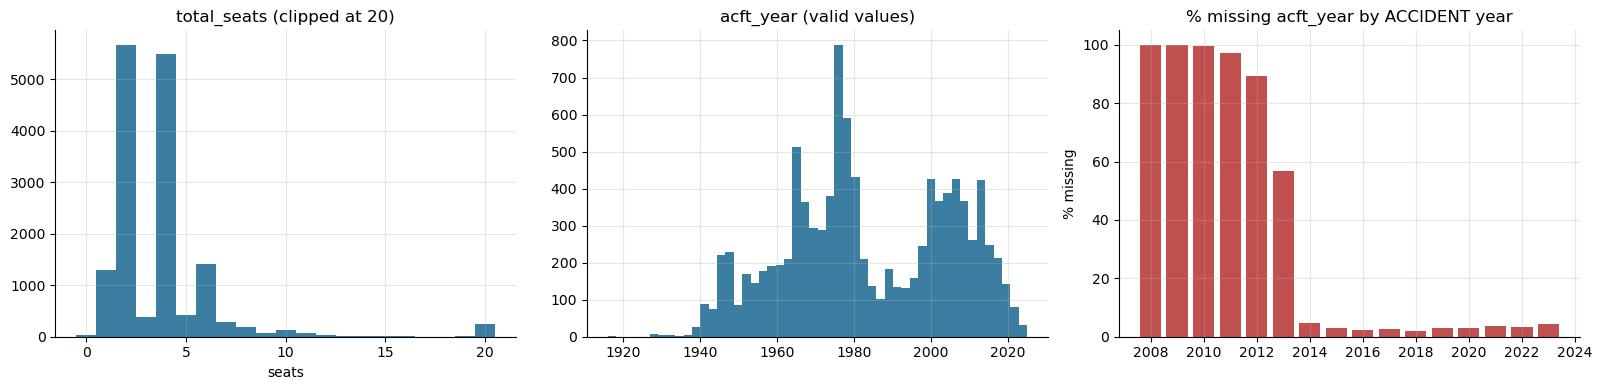

{2008: 100, 2009: 100, 2010: 99, 2011: 97, 2012: 89, 2013: 57, 2014: 5, 2015: 3, 2016: 2, 2017: 3, 2018: 2, 2019: 3, 2020: 3, 2021: 4, 2022: 3, 2023: 5}


In [29]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(A.total_seats.clip(upper=20).dropna(), bins=np.arange(-0.5, 21.5, 1), color="#3b7ea1")
ax[0].set_title("total_seats (clipped at 20)"); ax[0].set_xlabel("seats")
ax[1].hist(y[(y > 1900)].dropna(), bins=50, color="#3b7ea1"); ax[1].set_title("acft_year (valid values)")
miss = A.groupby("ev_year")["acft_year"].apply(lambda s: s.isna().mean())
ax[2].bar(miss.index, miss.values * 100, color="#c0504d"); ax[2].set_title("% missing acft_year by ACCIDENT year"); ax[2].set_ylabel("% missing")
plt.tight_layout(); plt.show()
print((miss * 100).round(0).astype(int).to_dict())

In [30]:
# Is missing acft_year informative?  Compare only the years where it is almost always present.
late = A[A.ev_year >= 2014]
print("ev_year >= 2014: share missing =", round(late.acft_year.isna().mean(), 3))
print("fatal rate, acft_year missing vs present (all years):", A.groupby(A.acft_year.isna())["fatal"].mean().round(3).to_dict())
print("fatal rate, acft_year missing vs present (2014+):    ", late.groupby(late.acft_year.isna())["fatal"].mean().round(3).to_dict())
print("fatal rate by aircraft-year band:")
print(A.groupby(pd.cut(A.acft_year, [1900, 1950, 1970, 1990, 2005, 2026]), observed=True)["fatal"].agg(["mean", "size"]).round(3))
print("\nfatal rate by seats band:")
print(A.groupby(pd.cut(A.total_seats, [-1, 1, 2, 4, 6, 10, 100, 1e5]), observed=True)["fatal"].agg(["mean", "size"]).round(3))

ev_year >= 2014: share missing = 0.032
fatal rate, acft_year missing vs present (all years): {False: 0.176, True: 0.161}
fatal rate, acft_year missing vs present (2014+):     {False: 0.169, True: 0.2}
fatal rate by aircraft-year band:
               mean  size
acft_year                
(1900, 1950]  0.124   756
(1950, 1970]  0.162  2253
(1970, 1990]  0.184  3110
(1990, 2005]  0.189  1847
(2005, 2026]  0.186  2194

fatal rate by seats band:
                    mean  size
total_seats                   
(-1.0, 1.0]        0.172  1332
(1.0, 2.0]         0.166  5663
(2.0, 4.0]         0.155  5879
(4.0, 6.0]         0.236  1849
(6.0, 10.0]        0.204   662
(10.0, 100.0]      0.141   220
(100.0, 100000.0]  0.006   168


**Interpretation.**
- **`total_seats`:** 37 rows with 0 seats (gliders and balloons mostly, so partly legitimate: pilot not counted) and **168 rows with > 100 seats, up to 8,300**. These are all airplanes, 158 of them `far_part 121` (airlines): large aircraft are real, but values like 1,979, 2,500, 3,300 or 8,300 are clearly typos (one is a year). Those 168 rows have a fatal rate of 0.6%, so "airliner" is a strong signal on its own. Odd/even counts are plausible.
- **`acft_year`:** 1 value of 0, 2 values below 1900 (163 and 1062) and **86 values later than the accident year** (almost always by 1 year, which may be a model-year convention rather than an error). Ages are otherwise plausible.
- **The 40% missing is not random: it is a time effect.** `acft_year` is missing in ~100% of 2008–2010, 89% in 2012, 57% in 2013 and only ~3% from 2014 on. So the missingness is a proxy for `ev_year` (probably a registration-data join that did not exist in the early years), not a property of the aircraft. Inside 2014+ the rows with missing `acft_year` have a fatal rate of 20% vs 17%: weak evidence.
- Fatal rate vs `acft_year` is mild (12% for pre-1950 up to ~19% for 1990+); vs seats, it peaks at 5–6 seats (24%) and collapses for > 100 (0.6%).

**→ NB1:** treat 0, <1900 and > `ev_year`+1 as `NaN`; for seats treat 0 as `NaN`, and either cap at a plausible maximum (e.g. 600) or create `is_large_aircraft` (> 20 seats). Add `acft_year_missing`; **check whether `ev_year` is stable between `learn` and `predict`** (Person 2 / Person 1): if the early years are in `predict` too, the indicator is safe, and imputing with the median/age is a reasonable choice. Consider using **aircraft age** (`ev_year − acft_year`) rather than the year.

## Part 4 · 7. The required feature `seat_vintage_ratio` (diagnostic only)

**What we do:** the project brief requires `seat_vintage_ratio = total_seats / acft_year` in every final model. NB0 must not create features, so here we only *compute it on a throw-away series* to see how it behaves, and flag questions for NB1.

> **Note for the group:** in the PDF, this requirement appears under section 3.3 (Target) but is numbered "5.2.1", which looks out of place (the document has no such subsection). Worth confirming with the teaching staff that it is intended before building on it.

inf values (acft_year == 0): 1 · NaN: 44.7%
{'count': 9392.0, 'mean': 0.00306, 'std': 0.01493, 'min': 0.0, '25%': 0.001, '50%': 0.00199, '75%': 0.00204, 'max': 1.0}

correlation(ratio, total_seats) on valid rows: 0.99994
share of rows where both inputs are present: 55.3%


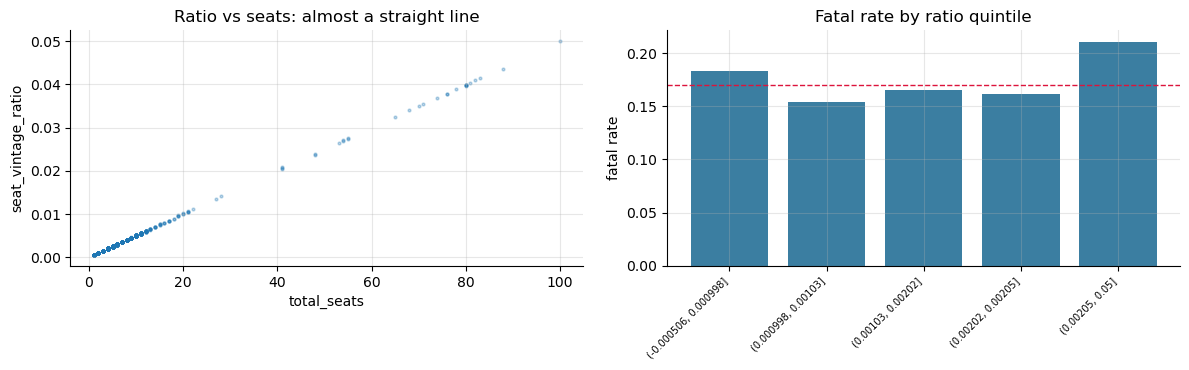

In [31]:
ratio = A["total_seats"] / A["acft_year"]          # throw-away series, not added to learn
print("inf values (acft_year == 0):", np.isinf(ratio).sum(), "· NaN:", f"{ratio.isna().mean():.1%}")
r = ratio.replace([np.inf, -np.inf], np.nan)
print(r.describe().round(5).to_dict())

ok = (A.acft_year > 1900) & A.total_seats.between(1, 100) & r.notna()
print("\ncorrelation(ratio, total_seats) on valid rows:", round(np.corrcoef(r[ok], A.total_seats[ok])[0, 1], 5))
print("share of rows where both inputs are present:", f"{(A.total_seats.notna() & A.acft_year.notna()).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(A.total_seats[ok], r[ok], s=4, alpha=.3); ax[0].set_xlabel("total_seats"); ax[0].set_ylabel("seat_vintage_ratio")
ax[0].set_title("Ratio vs seats: almost a straight line")
plot_num_vs_target(A[ok].assign(ratio=r[ok]), "ratio", q=5, ax=ax[1], title="Fatal rate by ratio quintile")
plt.tight_layout(); plt.show()

**Interpretation.**
- The feature is **undefined for ~45% of the rows** (`acft_year` or `total_seats` missing), explodes to `inf` when `acft_year = 0`, and is polluted by the impossible seat counts (a few absurd seat counts give outlying ratios).
- On valid rows it is **almost perfectly correlated with `total_seats`** (r ≈ 1.00): since years only vary between ~1900 and 2025 (±3%), dividing by them barely changes anything. So the "vintage" part adds essentially no information, and the signal it carries is the seat count itself.
- The brief's claim (denser seating in newer aircraft, slower evacuation) cannot really be tested with this ratio on this data: most accidents are in 2–4 seat light aircraft.

**→ NB1:** build it **after** cleaning (`acft_year` and `total_seats` repaired), decide how to handle `NaN` (the rule must be explicit and applied identically in `predict`), and justify it honestly in the feature engineering section, including its collinearity with `total_seats` (keep one of them in linear models). Question for the group: `acft_year` imputation strategy matters a lot here.

## Part 4 · 8. Relations inside the group

**What we do:** Spearman correlation between the numeric columns of this group and with `fatal`. We use a cleaned *copy* (impossible values → NaN) only so that outliers don't dominate.

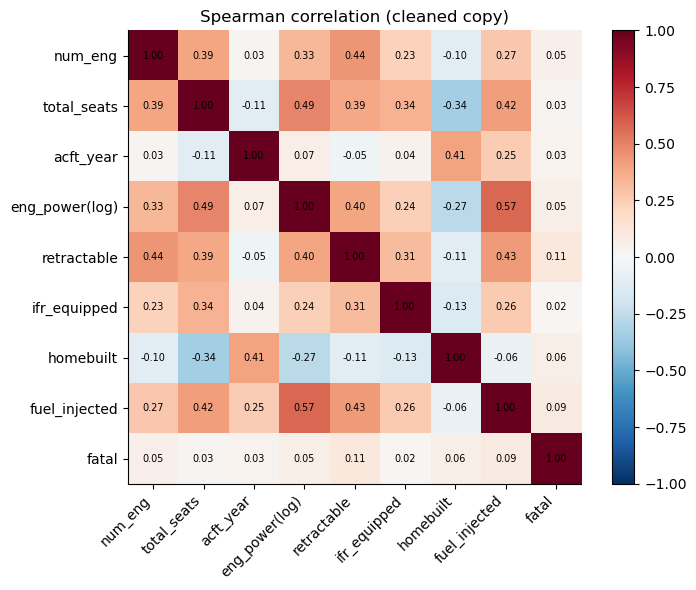

retractable       0.106
fuel_injected     0.091
homebuilt         0.060
eng_power(log)    0.055
num_eng           0.052
acft_year         0.034
total_seats       0.029
ifr_equipped      0.023
Name: fatal, dtype: float64


In [32]:
C = pd.DataFrame({
    "num_eng": A.num_eng,
    "total_seats": A.total_seats.where(A.total_seats.between(1, 100)),
    "acft_year": A.acft_year.where((A.acft_year > 1900) & (A.acft_year <= A.ev_year + 1)),
    "eng_power(log)": np.log10(A.eng_power.where(A.eng_power > 0)),
    "retractable": (A.fixed_retractable == "RETR").astype(int),
    "ifr_equipped": A.ifr_equipped_cert,
    "homebuilt": (A.homebuilt_u == "Y").astype(int),
    "fuel_injected": A.carb_fuel_injection.map({"FINJ": 1, "CARB": 0}),
    "fatal": A.fatal,
})
corr = C.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); plt.title("Spearman correlation (cleaned copy)"); plt.tight_layout(); plt.show()
print(corr["fatal"].drop("fatal").sort_values(key=abs, ascending=False).round(3))

**Interpretation.** The strongest links with `fatal` are modest (|ρ| of a few hundredths to ~0.1): `retractable`, `fuel_injected`, `homebuilt`, `num_eng`. No single aircraft variable is a silver bullet, so the value will come from combining them with flight-phase, pilot and weather information (interactions across groups, Person 5). Among themselves, `retractable`, `eng_power`, `num_eng`, `total_seats` and `fuel_injected` move together (bigger, more complex aircraft): redundancy to keep in mind for feature selection and for linear models.

**→ NB1:** consider a compound "aircraft complexity" feature or let tree-based models find the interactions; check VIF/regularisation if a linear model is used.

## Part 4 · 9. Findings and decisions for NB1 (input for Person 1's final table)

In [33]:
findings = pd.DataFrame([
    ("acft_category, homebuilt", "Mixed case (AIR/air, Y/y), ~25% lowercase, same in predict; lowercase carries no information", "Upper-case in both files; group categories with < 30 rows into OTHER"),
    ("acft_make", "2,914 raw values, long tail, ~2,300 appear once; 13% of predict rows have a make unseen in learn", "Normalise text; keep top 30-50 makes + OTHER; make_is_rare flag; encoding that handles unseen values and is fitted inside CV"),
    ("acft_make", "Big makes differ a lot (Boeing 3% ... Cirrus 33%) vs 17% base", "Keep as a feature (signal is real)"),
    ("carb_fuel_injection", "NaN is structural (not applicable to turbines/electric)", "Explicit category NOT_APPLICABLE vs UNKNOWN; do not impute"),
    ("eng_type", "Rare codes (HR, GTFN, LR, ELEC, NONE, UNK) with <= 23 rows", "Group rare codes into OTHER"),
    ("num_eng", "0 = gliders/balloons (valid); 3+ engines almost nonexistent", "Keep 0; cap at 3+"),
    ("eng_power", "Unit changes (HP vs lbs of thrust), 171 zeros, extreme outliers", "0 -> NaN; split into eng_power_hp and eng_thrust_lbs by eng_type; log/winsorise"),
    ("total_seats", "168 rows > 100 seats (some are typos, e.g. 8,300); 37 zeros", "0 -> NaN; cap or add is_large_aircraft; keep NaN indicator"),
    ("acft_year", "1 zero, 2 < 1900, 86 > ev_year (mostly by 1 year)", "Invalid -> NaN; use aircraft age (ev_year - acft_year)"),
    ("acft_year", "Missingness (40%) is a time effect: ~100% in 2008-2010, ~3% from 2014", "Add acft_year_missing; check ev_year distribution in learn vs predict; choose imputation consciously"),
    ("seat_vintage_ratio", "Required feature; NaN for ~45% of rows, inf when acft_year = 0, r ~ 1 with total_seats", "Build after cleaning; define NaN rule; justify honestly; confirm 5.2.1 with teachers"),
    ("fixed_retractable, num_eng, eng_power, total_seats", "Move together (aircraft complexity)", "Check redundancy in feature selection / VIF if linear model"),
], columns=["Column(s)", "Finding", "Decision / question for NB1"])
pd.set_option("display.max_colwidth", 120)
findings

,Column(s),Finding,Decision / question for NB1
0,"acft_category, homebuilt","Mixed case (AIR/air, Y/y), ~25% lowercase, same in predict; lowercase carries no information",Upper-case in both files; group categories with < 30 rows into OTHER
1,acft_make,"2,914 raw values, long tail, ~2,300 appear once; 13% of predict rows have a make unseen in learn",Normalise text; keep top 30-50 makes + OTHER; make_is_rare flag; encoding that handles unseen values and is fitted i...
2,acft_make,Big makes differ a lot (Boeing 3% ... Cirrus 33%) vs 17% base,Keep as a feature (signal is real)
3,carb_fuel_injection,NaN is structural (not applicable to turbines/electric),Explicit category NOT_APPLICABLE vs UNKNOWN; do not impute
4,eng_type,"Rare codes (HR, GTFN, LR, ELEC, NONE, UNK) with <= 23 rows",Group rare codes into OTHER
5,num_eng,0 = gliders/balloons (valid); 3+ engines almost nonexistent,Keep 0; cap at 3+
6,eng_power,"Unit changes (HP vs lbs of thrust), 171 zeros, extreme outliers",0 -> NaN; split into eng_power_hp and eng_thrust_lbs by eng_type; log/winsorise
7,total_seats,"168 rows > 100 seats (some are typos, e.g. 8,300); 37 zeros",0 -> NaN; cap or add is_large_aircraft; keep NaN indicator
8,acft_year,"1 zero, 2 < 1900, 86 > ev_year (mostly by 1 year)",Invalid -> NaN; use aircraft age (ev_year - acft_year)
9,acft_year,"Missingness (40%) is a time effect: ~100% in 2008-2010, ~3% from 2014",Add acft_year_missing; check ev_year distribution in learn vs predict; choose imputation consciously


# 7. Findings and decisions for NB1
One table with the main finding of every part and what NB1 should do with it. Each part defines its own table (`findings_p1`, `findings` for Part 4, `findings_p2`, `findings_p3`, `findings_p5`); this cell joins whichever ones exist, so it keeps working while the parts are being merged.

In [34]:
findings_p1 = pd.DataFrame([
    ("row_id", "Identifier only; no duplicated rows or ids", "Exclude from features"),
    ("ev_country", "Single value (USA) in both files", "Drop"),
    ("wx_temp_c", "Exact Celsius conversion of wx_temp (ρ = 1)", "Drop"),
    ("fatal", "Imbalanced: ~17% fatal; 'always 1' gives F1 ≈ 0.29", "Stratified CV, F1 as metric, class weights/resampling inside CV, tune the threshold"),
    ("all", "Most features have NaNs; rates equal in learn and predict", "Imputation per column, fitted on training folds only; no row dropping"),
    ("engine / sky blocks", "Columns go missing together (same source)", "Consistent imputation; one block-level missing flag"),
    ("apt_elev, sky_cond_nonceil, sky_cond_ceil, second_pilot, vis_sm", "Missingness is related to fatal (differences of 6-9 points)", "Add <col>_missing indicators"),
    ("wx_temp, wx_dew_pt, altimeter", "771 rows with all three = 0 = missing weather observation (altimeter 0 is impossible); fatal 6% vs 17.5%", "0 -> NaN; add weather_obs_missing flag"),
    ("eng_power, acft_year, pilot_age", "0 is impossible -> hidden missing", "0 -> NaN before imputation"),
    ("gust_ind", "Looks inverted vs gust_kts", "Question for Part 3: fix, recompute from gust_kts, or drop"),
    ("text columns", "Same category in different case (AIR/air, Y/y)", "strip + upper on learn and predict"),
    ("learn vs predict", "Same distributions (years, numeric, categorical)", "Stratified K-fold CV is a fair estimate of Kaggle; handle unseen categories"),
    ("numeric features", "Weak individual correlations with fatal (|ρ| ≤ 0.15)", "Combine features; try tree-based models; check multicollinearity for linear ones"),
], columns=["Column(s)", "Finding", "Decision / question for NB1"])

parts = {"1 Overview": "findings_p1", "2 When and where": "findings_p2", "3 Weather": "findings_p3",
         "4 Aircraft and engine": "findings", "5 Pilot and flight": "findings_p5"}
available = {name: globals()[var] for name, var in parts.items() if var in globals()}
print("parts included:", list(available), "· still missing:", [n for n in parts if n not in available])
all_findings = pd.concat(available, names=["Part", None]).reset_index(level=0)
pd.set_option("display.max_colwidth", 140)
all_findings.reset_index(drop=True)

parts included: ['1 Overview', '4 Aircraft and engine'] · still missing: ['2 When and where', '3 Weather', '5 Pilot and flight']


,Part,Column(s),Finding,Decision / question for NB1
0,1 Overview,row_id,Identifier only; no duplicated rows or ids,Exclude from features
1,1 Overview,ev_country,Single value (USA) in both files,Drop
2,1 Overview,wx_temp_c,Exact Celsius conversion of wx_temp (ρ = 1),Drop
3,1 Overview,fatal,Imbalanced: ~17% fatal; 'always 1' gives F1 ≈ 0.29,"Stratified CV, F1 as metric, class weights/resampling inside CV, tune the threshold"
4,1 Overview,all,Most features have NaNs; rates equal in learn and predict,"Imputation per column, fitted on training folds only; no row dropping"
5,1 Overview,engine / sky blocks,Columns go missing together (same source),Consistent imputation; one block-level missing flag
6,1 Overview,"apt_elev, sky_cond_nonceil, sky_cond_ceil, second_pilot, vis_sm",Missingness is related to fatal (differences of 6-9 points),Add <col>_missing indicators
7,1 Overview,"wx_temp, wx_dew_pt, altimeter",771 rows with all three = 0 = missing weather observation (altimeter 0 is impossible); fatal 6% vs 17.5%,0 -> NaN; add weather_obs_missing flag
8,1 Overview,"eng_power, acft_year, pilot_age",0 is impossible -> hidden missing,0 -> NaN before imputation
9,1 Overview,gust_ind,Looks inverted vs gust_kts,"Question for Part 3: fix, recompute from gust_kts, or drop"
